# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [1]:
# YOUR CODE HERE
# ============================================================
# Notebook 2 — Data Preparation
# Step: Load sampled_data.csv from Google Drive + dedup/null cleaning
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os

# ------------------------------------------------------------
# 0. Load sampled_data.csv from Google Drive
# ------------------------------------------------------------
DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"
DRIVE_PATH = os.path.join(DRIVE_DIR, "sampled_data.csv")

df = pd.read_csv(DRIVE_PATH)

print(f"Loaded dataset: {len(df):,} rows")
print(f"Columns: {list(df.columns)}")

size_before = len(df)

# ------------------------------------------------------------
# 1. Null / invalid record check on target columns
# ------------------------------------------------------------
required_cols = ["instruction", "intent", "category"]

print("\n--- Null counts (required columns) ---")
print(df[required_cols].isnull().sum())

null_rows = df[df[required_cols].isnull().any(axis=1)]
print(f"\nRows with nulls in required columns: {len(null_rows)}")

df = df.dropna(subset=required_cols).reset_index(drop=True)

empty_mask = (
    (df["instruction"].str.strip() == "") |
    (df["intent"].str.strip() == "") |
    (df["category"].str.strip() == "")
)
empty_count = empty_mask.sum()
if empty_count > 0:
    print(f"Rows with empty/whitespace-only required fields: {empty_count}")
    df = df[~empty_mask].reset_index(drop=True)

size_after_null_filter = len(df)
print(f"\nRows removed (nulls + empty/invalid): {size_before - size_after_null_filter}")

# ------------------------------------------------------------
# 2. Normalised deduplication (lowercase + strip)
# ------------------------------------------------------------
size_before_dedup = len(df)

df["instruction_norm"] = df["instruction"].str.lower().str.strip()

dupe_count = df.duplicated(subset=["instruction_norm"]).sum()
print(f"\nNormalised duplicate instructions found: {dupe_count}")

df = df.drop_duplicates(subset=["instruction_norm"], keep="first").reset_index(drop=True)
df = df.drop(columns=["instruction_norm"])

size_after_dedup = len(df)

# ------------------------------------------------------------
# 3. Audit summary
# ------------------------------------------------------------
print("\n" + "=" * 55)
print("CLEANING AUDIT SUMMARY")
print("=" * 55)
print(f"Original size (loaded):        {size_before:,}")
print(f"Removed — nulls/invalid:       {size_before - size_after_null_filter}")
print(f"Removed — normalised dupes:    {size_before_dedup - size_after_dedup}")
print(f"Total removed:                 {size_before - size_after_dedup}")
print(f"Final clean size:              {len(df):,}")

assert 1000 <= len(df) <= 5000, "Final size outside the required 1,000-5,000 range!"
assert df[required_cols].isnull().sum().sum() == 0, "Nulls still present after cleaning!"

print(f"\n✅ Dataset clean and within required range ({len(df):,} rows).")
print(f"Unique intents remaining: {df['intent'].nunique()}")

Mounted at /content/drive
Loaded dataset: 3,902 rows
Columns: ['flags', 'instruction', 'category', 'intent', 'response']

--- Null counts (required columns) ---
instruction    0
intent         0
category       0
dtype: int64

Rows with nulls in required columns: 0

Rows removed (nulls + empty/invalid): 0

Normalised duplicate instructions found: 0

CLEANING AUDIT SUMMARY
Original size (loaded):        3,902
Removed — nulls/invalid:       0
Removed — normalised dupes:    0
Total removed:                 0
Final clean size:              3,902

✅ Dataset clean and within required range (3,902 rows).
Unique intents remaining: 27


#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [2]:
# YOUR CODE HERE
# ============================================================
# Standardise string formatting: strip whitespace + enforce casing
# ============================================================

# ------------------------------------------------------------
# Before/after snapshot for audit purposes
# ------------------------------------------------------------
print("--- Before cleaning (sample) ---")
print(df[["instruction", "intent", "category"]].head(3))

sample_intents_before = df["intent"].unique()[:5]
sample_categories_before = df["category"].unique()[:5]
print(f"\nSample intents before: {list(sample_intents_before)}")
print(f"Sample categories before: {list(sample_categories_before)}")

# ------------------------------------------------------------
# 1. instruction — strip whitespace only (preserve original casing;
#    this is free-text the model reads and generates, not a class label)
# ------------------------------------------------------------
df["instruction"] = df["instruction"].str.strip()

# ------------------------------------------------------------
# 2. intent — strip whitespace BEFORE lowering
#    (trailing spaces survive .lower(), so order matters)
# ------------------------------------------------------------
df["intent"] = df["intent"].str.strip().str.lower()

# ------------------------------------------------------------
# 3. category — strip whitespace BEFORE uppering
# ------------------------------------------------------------
df["category"] = df["category"].str.strip().str.upper()

# ------------------------------------------------------------
# After snapshot
# ------------------------------------------------------------
print("\n--- After cleaning (sample) ---")
print(df[["instruction", "intent", "category"]].head(3))

sample_intents_after = df["intent"].unique()[:5]
sample_categories_after = df["category"].unique()[:5]
print(f"\nSample intents after: {list(sample_intents_after)}")
print(f"Sample categories after: {list(sample_categories_after)}")

# ------------------------------------------------------------
# 4. Verify no casing/whitespace variants collapsed the class count
#    (would indicate inconsistent casing existed pre-cleaning)
# ------------------------------------------------------------
print(f"\nUnique intents: {df['intent'].nunique()}")
print(f"Unique categories: {df['category'].nunique()}")

# ------------------------------------------------------------
# 5. Confirm no leading/trailing whitespace remains anywhere
# ------------------------------------------------------------
has_whitespace_issue = (
    (df["instruction"] != df["instruction"].str.strip()).any() or
    (df["intent"] != df["intent"].str.strip()).any() or
    (df["category"] != df["category"].str.strip()).any()
)
print(f"\nResidual whitespace issues: {'⚠️ Found' if has_whitespace_issue else '✅ None'}")

print(f"\nFinal row count: {len(df):,}")

--- Before cleaning (sample) ---
                                         instruction               intent  \
0                   I can't talk with  a human agent  contact_human_agent   
1  I have got to locate hte bills from {{Person N...        check_invoice   
2  I cannot pay, help me to inform of a problem w...        payment_issue   

  category  
0  CONTACT  
1  INVOICE  
2  PAYMENT  

Sample intents before: ['contact_human_agent', 'check_invoice', 'payment_issue', 'contact_customer_service', 'check_payment_methods']
Sample categories before: ['CONTACT', 'INVOICE', 'PAYMENT', 'SUBSCRIPTION', 'CANCEL']

--- After cleaning (sample) ---
                                         instruction               intent  \
0                   I can't talk with  a human agent  contact_human_agent   
1  I have got to locate hte bills from {{Person N...        check_invoice   
2  I cannot pay, help me to inform of a problem w...        payment_issue   

  category  
0  CONTACT  
1  INVOICE  
2  P

### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [3]:
# YOUR CODE HERE
# ============================================================
# ChatML formatting with strict JSON targets
# ============================================================

import json
from transformers import AutoTokenizer

# ------------------------------------------------------------
# 0. Model selection — MUST be identical across ALL notebooks
#    (Notebook 1's EDA already used this same MODEL_ID for
#    token length analysis — keep it consistent here and in
#    NB3 Baseline, NB4 RAG, NB6 Fine-Tuning, NB7 Hybrid eval)
# ------------------------------------------------------------
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Qwen2.5-Instruct ships a chat template; confirm it's present
print(f"Tokenizer loaded: {MODEL_ID}")
print(f"Chat template available: {tokenizer.chat_template is not None}")

# ------------------------------------------------------------
# 1. Define a system prompt for the intent-router role
#    (kept identical across all rows — this is what Stage 4's
#    fine-tuning will teach the model to follow consistently)
# ------------------------------------------------------------
SYSTEM_PROMPT = (
    "You are a customer support intent classification assistant. "
    "Given a customer query, respond with ONLY a valid JSON object "
    "containing exactly two keys: \"intent\" and \"category\". "
    "Do not include any explanation, markdown formatting, or additional text."
)

# ------------------------------------------------------------
# 2. Build the strict JSON target string per row
# ------------------------------------------------------------
def build_json_target(row):
    target_obj = {
        "intent": row["intent"],
        "category": row["category"]
    }
    # json.dumps with no extra whitespace -> compact, deterministic format
    return json.dumps(target_obj, separators=(",", ":"))

df["json_target"] = df.apply(build_json_target, axis=1)

print("\n--- Sample JSON targets ---")
print(df["json_target"].head(3).tolist())

# ------------------------------------------------------------
# 3. Wrap each row into ChatML using apply_chat_template
# ------------------------------------------------------------
def build_chatml(row):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": row["instruction"]},
        {"role": "assistant", "content": row["json_target"]},
    ]
    # tokenize=False -> returns the formatted string, not token ids;
    # tokenization happens as a separate, explicit step later
    return tokenizer.apply_chat_template(messages, tokenize=False)

df["chatml_text"] = df.apply(build_chatml, axis=1)

print("\n--- Sample ChatML-formatted record ---")
print(df["chatml_text"].iloc[0])

# ------------------------------------------------------------
# 4. Validate every JSON target actually parses (catches any
#    stray characters from unclean intent/category strings)
# ------------------------------------------------------------
invalid_json_count = 0
for idx, target in enumerate(df["json_target"]):
    try:
        json.loads(target)
    except json.JSONDecodeError:
        invalid_json_count += 1
        print(f"⚠️ Invalid JSON at row {idx}: {target}")

print(f"\nInvalid JSON targets: {invalid_json_count} / {len(df)}")
if invalid_json_count == 0:
    print("✅ All JSON targets are valid and parseable.")

# ------------------------------------------------------------
# 5. Also build a "prompt-only" version (system + user, no assistant
#    turn) — this is what Stage 3 baseline/RAG inference will feed
#    the model, with add_generation_prompt=True so it knows to respond
# ------------------------------------------------------------
def build_chatml_prompt_only(row):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": row["instruction"]},
    ]
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

df["chatml_prompt"] = df.apply(build_chatml_prompt_only, axis=1)

print("\n--- Sample prompt-only ChatML (for inference) ---")
print(df["chatml_prompt"].iloc[0])

print(f"\nFinal row count: {len(df):,}")
print(f"New columns added: json_target, chatml_text, chatml_prompt")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizer loaded: Qwen/Qwen2.5-1.5B-Instruct
Chat template available: True

--- Sample JSON targets ---
['{"intent":"contact_human_agent","category":"CONTACT"}', '{"intent":"check_invoice","category":"INVOICE"}', '{"intent":"payment_issue","category":"PAYMENT"}']

--- Sample ChatML-formatted record ---
<|im_start|>system
You are a customer support intent classification assistant. Given a customer query, respond with ONLY a valid JSON object containing exactly two keys: "intent" and "category". Do not include any explanation, markdown formatting, or additional text.<|im_end|>
<|im_start|>user
I can't talk with  a human agent<|im_end|>
<|im_start|>assistant
{"intent":"contact_human_agent","category":"CONTACT"}<|im_end|>


Invalid JSON targets: 0 / 3902
✅ All JSON targets are valid and parseable.

--- Sample prompt-only ChatML (for inference) ---
<|im_start|>system
You are a customer support intent classification assistant. Given a customer query, respond with ONLY a valid JSON object con

#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [6]:
# YOUR CODE HERE
import json

def extract_and_validate_assistant_json(chatml_text):
    parts = chatml_text.split("<|im_start|>assistant")
    if len(parts) < 2:
        return None, None, "No assistant marker found"

    assistant_section = parts[-1]
    assistant_section = assistant_section.replace("<|im_end|>", "").strip()

    try:
        parsed = json.loads(assistant_section)
        return parsed, assistant_section, None
    except json.JSONDecodeError as e:
        return None, assistant_section, str(e)


validation_errors = []
parsed_targets = []

for idx in range(len(df)):
    chatml_text = df["chatml_text"].iloc[idx]
    parsed, raw_extracted, error = extract_and_validate_assistant_json(chatml_text)
    if error:
        validation_errors.append((idx, raw_extracted, error))
    else:
        parsed_targets.append(parsed)

print("Total rows checked:", len(df))
print("Successfully parsed:", len(parsed_targets))
print("Failed to parse:", len(validation_errors))

if validation_errors:
    print("")
    print("Validation errors found:")
    for idx, raw, err in validation_errors[:10]:
        print("  Row", idx, "error:", err, "raw:", raw)
else:
    print("")
    print("All rows extracted and parsed successfully.")

print("")
print("--- Spot-check: 5 random samples ---")
sample_df = df.sample(5, random_state=42)

for idx in sample_df.index:
    chatml_text = df.loc[idx, "chatml_text"]
    parsed, raw_extracted, error = extract_and_validate_assistant_json(chatml_text)

    print("")
    print("Row", idx, ":")
    print("  Extracted raw:", raw_extracted)
    print("  Parsed:", parsed)

    if parsed is not None:
        keys_match = set(parsed.keys()) == {"intent", "category"}
        intent_match = parsed.get("intent") == df.loc[idx, "intent"]
        category_match = parsed.get("category") == df.loc[idx, "category"]
        print("  Keys correct:", keys_match)
        print("  Intent matches source:", intent_match)
        print("  Category matches source:", category_match)

        if not (keys_match and intent_match and category_match):
            print("  MISMATCH DETECTED")
    else:
        print("  FAILED TO PARSE:", error)

assert len(validation_errors) == 0, str(len(validation_errors)) + " rows failed JSON validation"

print("")
print("Structural integrity check passed - safe to proceed to tokenization.")

Total rows checked: 3902
Successfully parsed: 3902
Failed to parse: 0

All rows extracted and parsed successfully.

--- Spot-check: 5 random samples ---

Row 948 :
  Extracted raw: {"intent":"change_shipping_address","category":"SHIPPING"}
  Parsed: {'intent': 'change_shipping_address', 'category': 'SHIPPING'}
  Keys correct: True
  Intent matches source: True
  Category matches source: True

Row 3036 :
  Extracted raw: {"intent":"check_refund_policy","category":"REFUND"}
  Parsed: {'intent': 'check_refund_policy', 'category': 'REFUND'}
  Keys correct: True
  Intent matches source: True
  Category matches source: True

Row 1960 :
  Extracted raw: {"intent":"check_refund_policy","category":"REFUND"}
  Parsed: {'intent': 'check_refund_policy', 'category': 'REFUND'}
  Keys correct: True
  Intent matches source: True
  Category matches source: True

Row 3543 :
  Extracted raw: {"intent":"switch_account","category":"ACCOUNT"}
  Parsed: {'intent': 'switch_account', 'category': 'ACCOUNT'}
  K

### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [7]:
# YOUR CODE HERE
import numpy as np

MAX_LENGTH = 128  # adjust to 256 if you see truncation warnings below

def tokenize_and_mask(chatml_text, tokenizer, max_length=MAX_LENGTH):
    encoding = tokenizer(
        chatml_text,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )

    input_ids = encoding["input_ids"][0]
    attention_mask = encoding["attention_mask"][0]

    labels = input_ids.copy()
    labels[input_ids == tokenizer.pad_token_id] = -100

    return input_ids, attention_mask, labels


if tokenizer.pad_token_id is None:
    print("pad_token_id is None, setting pad_token to eos_token")
    tokenizer.pad_token = tokenizer.eos_token

print("pad_token:", tokenizer.pad_token)
print("pad_token_id:", tokenizer.pad_token_id)

all_input_ids = []
all_attention_masks = []
all_labels = []
truncated_count = 0

for idx in range(len(df)):
    chatml_text = df["chatml_text"].iloc[idx]

    full_ids = tokenizer(chatml_text, truncation=False)["input_ids"]
    if len(full_ids) > MAX_LENGTH:
        truncated_count = truncated_count + 1

    input_ids, attention_mask, labels = tokenize_and_mask(chatml_text, tokenizer)

    all_input_ids.append(input_ids)
    all_attention_masks.append(attention_mask)
    all_labels.append(labels)

print("Total rows tokenized:", len(all_input_ids))
print("Rows truncated at max_length =", MAX_LENGTH, ":", truncated_count)
print("Truncation rate:", round(100 * truncated_count / len(df), 2), "percent")

print("")
print("--- Sample check: row 0 ---")
print("input_ids shape:", all_input_ids[0].shape)
print("attention_mask shape:", all_attention_masks[0].shape)
print("labels shape:", all_labels[0].shape)

pad_positions = np.where(all_input_ids[0] == tokenizer.pad_token_id)[0]
print("Number of pad tokens in row 0:", len(pad_positions))

if len(pad_positions) > 0:
    labels_at_pad = all_labels[0][pad_positions]
    all_masked = np.all(labels_at_pad == -100)
    print("All pad positions correctly set to -100 in labels:", all_masked)
else:
    print("Row 0 has no padding (sequence filled max_length exactly)")

non_pad_positions = np.where(all_input_ids[0] != tokenizer.pad_token_id)[0]
labels_at_non_pad = all_labels[0][non_pad_positions]
input_at_non_pad = all_input_ids[0][non_pad_positions]
non_pad_preserved = np.array_equal(labels_at_non_pad, input_at_non_pad)
print("Non-pad labels match input_ids (unmasked):", non_pad_preserved)

print("")
print("--- Global validation across all rows ---")
mismatch_count = 0
for i in range(len(all_input_ids)):
    ids = all_input_ids[i]
    lbl = all_labels[i]
    pad_mask = ids == tokenizer.pad_token_id
    if not np.all(lbl[pad_mask] == -100):
        mismatch_count = mismatch_count + 1
    if not np.array_equal(lbl[~pad_mask], ids[~pad_mask]):
        mismatch_count = mismatch_count + 1

print("Rows with masking mismatch:", mismatch_count)
if mismatch_count == 0:
    print("All rows correctly masked: pad tokens set to -100, non-pad tokens preserved.")

pad_token: <|endoftext|>
pad_token_id: 151643
Total rows tokenized: 3902
Rows truncated at max_length = 128 : 0
Truncation rate: 0.0 percent

--- Sample check: row 0 ---
input_ids shape: (128,)
attention_mask shape: (128,)
labels shape: (128,)
Number of pad tokens in row 0: 47
All pad positions correctly set to -100 in labels: True
Non-pad labels match input_ids (unmasked): True

--- Global validation across all rows ---
Rows with masking mismatch: 0
All rows correctly masked: pad tokens set to -100, non-pad tokens preserved.


#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

--- True token-count distribution (untruncated) ---
Min: 72
Max: 94
Mean: 82.2
Median: 82
95th percentile: 88
99th percentile: 91


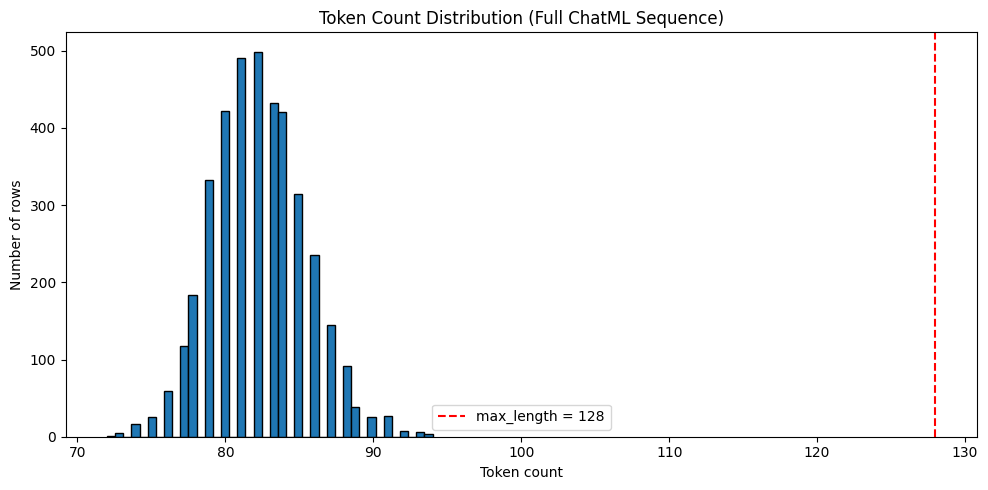


--- Truncation risk check ---
Rows hitting or exceeding max_length = 128 : 0
Percentage: 0.0 percent
OK: Truncation rate is within acceptable bounds (<= 5 percent).

--- Non-padding token count per row (from already-tokenized arrays) ---


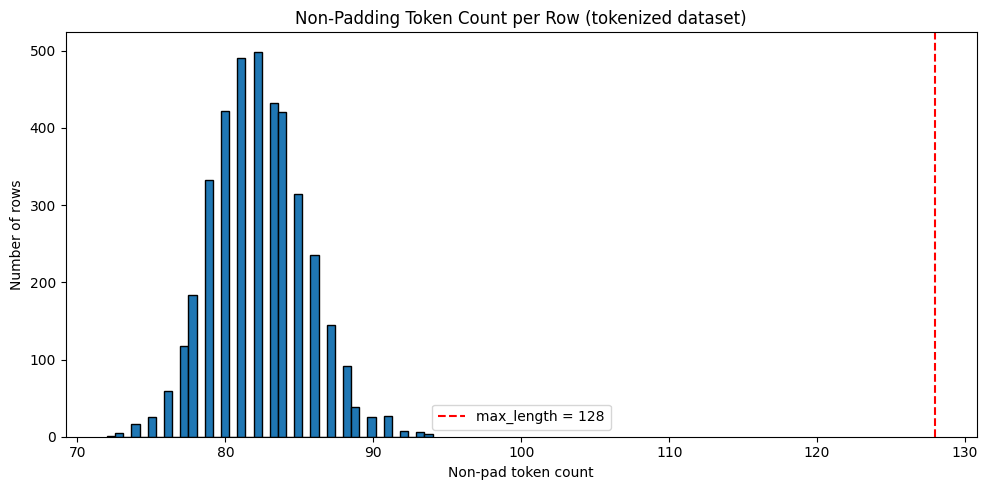

Min non-pad tokens: 72
Max non-pad tokens: 94
Mean non-pad tokens: 82.2

--- JSON target token length check ---
JSON target token length - min: 10
JSON target token length - max: 13
JSON target token length - mean: 11.1

--- Headroom check ---
Minimum headroom (max_length - actual length) across all rows: 34
OK: Headroom is sufficient for the JSON target length in all rows.


In [8]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import numpy as np

true_lengths = []

for idx in range(len(df)):
    chatml_text = df["chatml_text"].iloc[idx]
    full_ids = tokenizer(chatml_text, truncation=False)["input_ids"]
    true_lengths.append(len(full_ids))

true_lengths = np.array(true_lengths)

print("--- True token-count distribution (untruncated) ---")
print("Min:", true_lengths.min())
print("Max:", true_lengths.max())
print("Mean:", round(true_lengths.mean(), 1))
print("Median:", int(np.median(true_lengths)))
print("95th percentile:", int(np.percentile(true_lengths, 95)))
print("99th percentile:", int(np.percentile(true_lengths, 99)))

plt.figure(figsize=(10, 5))
plt.hist(true_lengths, bins=40, edgecolor="black")
plt.axvline(MAX_LENGTH, color="red", linestyle="--", label="max_length = " + str(MAX_LENGTH))
plt.title("Token Count Distribution (Full ChatML Sequence)")
plt.xlabel("Token count")
plt.ylabel("Number of rows")
plt.legend()
plt.tight_layout()
plt.show()

rows_at_or_over_max = np.sum(true_lengths >= MAX_LENGTH)
pct_at_or_over_max = 100 * rows_at_or_over_max / len(true_lengths)

print("")
print("--- Truncation risk check ---")
print("Rows hitting or exceeding max_length =", MAX_LENGTH, ":", rows_at_or_over_max)
print("Percentage:", round(pct_at_or_over_max, 2), "percent")

if pct_at_or_over_max > 5:
    print("WARNING: More than 5 percent of rows are being truncated. Increase max_length to 256.")
else:
    print("OK: Truncation rate is within acceptable bounds (<= 5 percent).")

print("")
print("--- Non-padding token count per row (from already-tokenized arrays) ---")
non_pad_counts = []
for i in range(len(all_input_ids)):
    ids = all_input_ids[i]
    non_pad = np.sum(ids != tokenizer.pad_token_id)
    non_pad_counts.append(non_pad)

non_pad_counts = np.array(non_pad_counts)

plt.figure(figsize=(10, 5))
plt.hist(non_pad_counts, bins=40, edgecolor="black")
plt.axvline(MAX_LENGTH, color="red", linestyle="--", label="max_length = " + str(MAX_LENGTH))
plt.title("Non-Padding Token Count per Row (tokenized dataset)")
plt.xlabel("Non-pad token count")
plt.ylabel("Number of rows")
plt.legend()
plt.tight_layout()
plt.show()

print("Min non-pad tokens:", non_pad_counts.min())
print("Max non-pad tokens:", non_pad_counts.max())
print("Mean non-pad tokens:", round(non_pad_counts.mean(), 1))

print("")
print("--- JSON target token length check ---")
json_target_lengths = []
for idx in range(len(df)):
    json_ids = tokenizer(df["json_target"].iloc[idx], truncation=False)["input_ids"]
    json_target_lengths.append(len(json_ids))

json_target_lengths = np.array(json_target_lengths)
print("JSON target token length - min:", json_target_lengths.min())
print("JSON target token length - max:", json_target_lengths.max())
print("JSON target token length - mean:", round(json_target_lengths.mean(), 1))

space_left_at_max = MAX_LENGTH - true_lengths
min_space_left = space_left_at_max.min()
print("")
print("--- Headroom check ---")
print("Minimum headroom (max_length - actual length) across all rows:", min_space_left)
if min_space_left < json_target_lengths.max():
    print("WARNING: Some rows may not have enough headroom to fit the full JSON target if near max_length.")
else:
    print("OK: Headroom is sufficient for the JSON target length in all rows.")

#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [9]:
# YOUR CODE HERE
!pip install -q langchain langchain-community

from langchain_community.document_loaders import TextLoader
import glob
import os

POLICY_DIR = "corporate_policies"

policy_files = sorted(glob.glob(os.path.join(POLICY_DIR, "*.md")))
print("Found", len(policy_files), "policy files to ingest")

documents = []

for fpath in policy_files:
    loader = TextLoader(fpath, encoding="utf-8")
    loaded_docs = loader.load()

    for doc in loaded_docs:
        doc.metadata["source_file"] = os.path.basename(fpath)
        doc.metadata["policy_name"] = os.path.splitext(os.path.basename(fpath))[0]

    documents.extend(loaded_docs)

print("")
print("Total Document objects created:", len(documents))

print("")
print("--- Sample Document object (first one) ---")
print("Metadata:", documents[0].metadata)
print("Page content (first 300 chars):")
print(documents[0].page_content[:300])

print("")
print("--- Verify one Document per file ---")
if len(documents) == len(policy_files):
    print("OK: One Document created per policy file (" + str(len(documents)) + " total).")
else:
    print("WARNING: Document count (" + str(len(documents)) + ") does not match file count (" + str(len(policy_files)) + ").")

print("")
print("--- Document content length summary ---")
content_lengths = [len(doc.page_content) for doc in documents]
print("Min characters:", min(content_lengths))
print("Max characters:", max(content_lengths))
print("Mean characters:", round(sum(content_lengths) / len(content_lengths), 1))

print("")
print("--- All documents with metadata ---")
for doc in documents:
    print(doc.metadata["policy_name"], "-", len(doc.page_content), "characters")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/tmp/ipykernel_560/3533392746.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


Found 13 policy files to ingest

Total Document objects created: 13

--- Sample Document object (first one) ---
Metadata: {'source': 'corporate_policies/account_recovery.md', 'source_file': 'account_recovery.md', 'policy_name': 'account_recovery'}
Page content (first 300 chars):
# Account Recovery

## When To Use
Use this procedure when a customer cannot access their account due to a
lockout, a lost email address, suspected unauthorized access, or a disabled
account — anything beyond a simple forgotten password (see the password reset
procedure for that case).

## Identity 

--- Verify one Document per file ---
OK: One Document created per policy file (13 total).

--- Document content length summary ---
Min characters: 1521
Max characters: 1742
Mean characters: 1602.7

--- All documents with metadata ---
account_recovery - 1553 characters
billing_disputes - 1661 characters
data_privacy - 1721 characters
escalation_matrix - 1550 characters
order_tracking - 1534 characters
password_reset

### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [10]:
# YOUR CODE HERE
from sklearn.model_selection import train_test_split
import numpy as np

df = df.reset_index(drop=True)
df["row_idx"] = df.index

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["intent"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["intent"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("--- Split sizes ---")
print("Train:", len(train_df), "(", round(100 * len(train_df) / len(df), 1), "percent )")
print("Validation:", len(val_df), "(", round(100 * len(val_df) / len(df), 1), "percent )")
print("Test:", len(test_df), "(", round(100 * len(test_df) / len(df), 1), "percent )")
print("Total:", len(train_df) + len(val_df) + len(test_df), "vs original:", len(df))

print("")
print("--- Stratification check: intent classes present in each split ---")
print("Unique intents in train:", train_df["intent"].nunique())
print("Unique intents in val:", val_df["intent"].nunique())
print("Unique intents in test:", test_df["intent"].nunique())
print("Unique intents in original:", df["intent"].nunique())

print("")
print("--- Per-intent minimum count check (val/test are the thin ones) ---")
print("Min per-intent count in train:", train_df["intent"].value_counts().min())
print("Min per-intent count in val:", val_df["intent"].value_counts().min())
print("Min per-intent count in test:", test_df["intent"].value_counts().min())

print("")
print("--- Data leakage verification (set-intersection checks) ---")

train_ids = set(train_df["row_idx"])
val_ids = set(val_df["row_idx"])
test_ids = set(test_df["row_idx"])

assert len(train_ids & val_ids) == 0, "Leakage detected between train and val (row_idx)"
assert len(train_ids & test_ids) == 0, "Leakage detected between train and test (row_idx)"
assert len(val_ids & test_ids) == 0, "Leakage detected between val and test (row_idx)"
print("Row-index leakage check: PASSED (zero overlap across all three splits)")

train_instr = set(train_df["instruction"].str.lower().str.strip())
val_instr = set(val_df["instruction"].str.lower().str.strip())
test_instr = set(test_df["instruction"].str.lower().str.strip())

assert len(train_instr & val_instr) == 0, "Leakage detected between train and val (instruction text)"
assert len(train_instr & test_instr) == 0, "Leakage detected between train and test (instruction text)"
assert len(val_instr & test_instr) == 0, "Leakage detected between val and test (instruction text)"
print("Normalised instruction-text leakage check: PASSED (zero overlap across all three splits)")

print("")
print("All partitions confirmed independent. Zero data leakage across train, validation, and test.")

# ------------------------------------------------------------
# Build df_test: readable text/intent/category columns for later
# scoring in Notebook 5 (RAG eval) and Notebook 7 (Hybrid eval)
# ------------------------------------------------------------
df_test = test_df[["instruction", "intent", "category", "json_target", "chatml_prompt"]].copy()
df_test = df_test.rename(columns={"instruction": "text"})

print("")
print("--- df_test preview ---")
print(df_test.head(3))
print("")
print("df_test shape:", df_test.shape)

# ------------------------------------------------------------
# Save df_test.csv (required by NB5 and NB7 per this notebook's
# stated output dependencies)
# ------------------------------------------------------------
DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"
df_test_path = DRIVE_DIR + "/df_test.csv"
df_test.to_csv(df_test_path, index=False)
print("Saved df_test.csv to:", df_test_path)

--- Split sizes ---
Train: 3121 ( 80.0 percent )
Validation: 390 ( 10.0 percent )
Test: 391 ( 10.0 percent )
Total: 3902 vs original: 3902

--- Stratification check: intent classes present in each split ---
Unique intents in train: 27
Unique intents in val: 27
Unique intents in test: 27
Unique intents in original: 27

--- Per-intent minimum count check (val/test are the thin ones) ---
Min per-intent count in train: 86
Min per-intent count in val: 11
Min per-intent count in test: 11

--- Data leakage verification (set-intersection checks) ---
Row-index leakage check: PASSED (zero overlap across all three splits)
Normalised instruction-text leakage check: PASSED (zero overlap across all three splits)

All partitions confirmed independent. Zero data leakage across train, validation, and test.

--- df_test preview ---
                                                text                   intent  \
0               need help to shop several of ur item              place_order   
1  i need as

---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [11]:
# YOUR CODE HERE
from datasets import Dataset, DatasetDict
import numpy as np
import os

MAX_LENGTH = 128  # must match the value used in Notebook 2 earlier, and in NB6/NB3/NB5/NB7

def tokenize_and_mask_row(chatml_text, chatml_prompt, tokenizer, max_length=MAX_LENGTH):
    encoding = tokenizer(
        chatml_text,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )
    input_ids = encoding["input_ids"][0]
    attention_mask = encoding["attention_mask"][0]

    # Mask the system+user portion so loss is computed only on the
    # assistant's JSON response, not the fixed prompt text.
    prompt_ids = tokenizer(chatml_prompt, truncation=True, max_length=max_length)["input_ids"]
    prompt_len = len(prompt_ids)

    labels = input_ids.copy()
    labels[:prompt_len] = -100
    labels[input_ids == tokenizer.pad_token_id] = -100

    return input_ids, attention_mask, labels


def build_hf_dataset(source_df, tokenizer, max_length=MAX_LENGTH):
    all_input_ids = []
    all_attention_masks = []
    all_labels = []

    for idx in range(len(source_df)):
        chatml_text = source_df["chatml_text"].iloc[idx]
        chatml_prompt = source_df["chatml_prompt"].iloc[idx]

        input_ids, attention_mask, labels = tokenize_and_mask_row(
            chatml_text, chatml_prompt, tokenizer, max_length
        )

        all_input_ids.append(input_ids.tolist())
        all_attention_masks.append(attention_mask.tolist())
        all_labels.append(labels.tolist())

    dataset = Dataset.from_dict({
        "input_ids": all_input_ids,
        "attention_mask": all_attention_masks,
        "labels": all_labels,
        "intent": source_df["intent"].tolist(),
        "category": source_df["category"].tolist(),
        "instruction": source_df["instruction"].tolist(),
    })
    return dataset


print("Building tokenized datasets...")
tokenized_train = build_hf_dataset(train_df, tokenizer)
tokenized_valid = build_hf_dataset(val_df, tokenizer)
tokenized_test = build_hf_dataset(test_df, tokenizer)

print("")
print("--- Dataset sizes ---")
print("tokenized_train:", len(tokenized_train))
print("tokenized_valid:", len(tokenized_valid))
print("tokenized_test:", len(tokenized_test))

print("")
print("--- Schema check (train) ---")
print(tokenized_train)

print("")
print("--- Sample row 0 (train) ---")
sample = tokenized_train[0]
print("input_ids length:", len(sample["input_ids"]))
print("attention_mask length:", len(sample["attention_mask"]))
print("labels length:", len(sample["labels"]))
print("intent:", sample["intent"])
print("category:", sample["category"])

non_masked_labels = sum(1 for l in sample["labels"] if l != -100)
print("Non-masked label tokens (should equal JSON target length + im_end):", non_masked_labels)

# ------------------------------------------------------------
# Save locally first (fast, working directory)
# ------------------------------------------------------------
tokenized_train.save_to_disk("./tokenized_train")
tokenized_valid.save_to_disk("./tokenized_valid")
tokenized_test.save_to_disk("./tokenized_test")

print("")
print("Saved locally: ./tokenized_train, ./tokenized_valid, ./tokenized_test")

# ------------------------------------------------------------
# Persist to Google Drive so they survive runtime disconnects
# (matches artifacts folder used throughout this project)
# ------------------------------------------------------------
DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"
os.makedirs(DRIVE_DIR, exist_ok=True)

tokenized_train.save_to_disk(DRIVE_DIR + "/tokenized_train")
tokenized_valid.save_to_disk(DRIVE_DIR + "/tokenized_valid")
tokenized_test.save_to_disk(DRIVE_DIR + "/tokenized_test")

print("Saved to Drive:", DRIVE_DIR + "/tokenized_train, tokenized_valid, tokenized_test")

# ------------------------------------------------------------
# Final verification: reload from disk to confirm integrity
# ------------------------------------------------------------
from datasets import load_from_disk

reloaded_train = load_from_disk("./tokenized_train")
reloaded_valid = load_from_disk("./tokenized_valid")
reloaded_test = load_from_disk("./tokenized_test")

assert len(reloaded_train) == len(train_df), "Train reload size mismatch!"
assert len(reloaded_valid) == len(val_df), "Valid reload size mismatch!"
assert len(reloaded_test) == len(test_df), "Test reload size mismatch!"

print("")
print("Reload verification PASSED - all three saved datasets match expected sizes.")
print("")
print("NB6 (fine-tuning) can now load these via load_from_disk('tokenized_train') etc.")

Building tokenized datasets...

--- Dataset sizes ---
tokenized_train: 3121
tokenized_valid: 390
tokenized_test: 391

--- Schema check (train) ---
Dataset({
    features: ['input_ids', 'attention_mask', 'labels', 'intent', 'category', 'instruction'],
    num_rows: 3121
})

--- Sample row 0 (train) ---
input_ids length: 128
attention_mask length: 128
labels length: 128
intent: set_up_shipping_address
category: SHIPPING
Non-masked label tokens (should equal JSON target length + im_end): 15


Saving the dataset (0/1 shards):   0%|          | 0/3121 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/391 [00:00<?, ? examples/s]


Saved locally: ./tokenized_train, ./tokenized_valid, ./tokenized_test


Saving the dataset (0/1 shards):   0%|          | 0/3121 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/391 [00:00<?, ? examples/s]

Saved to Drive: /content/drive/MyDrive/customer_support_llm_project/artifacts/tokenized_train, tokenized_valid, tokenized_test

Reload verification PASSED - all three saved datasets match expected sizes.

NB6 (fine-tuning) can now load these via load_from_disk('tokenized_train') etc.


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**